# 05 High-Accuracy Custom CNN Training (40 Epochs: 20 + 20 Staged Resumable Pipeline)

## 🎯 Objective & Strategy
Train an advanced custom deep convolutional neural network targeting **95%+ accuracy** across all 40 crop leaf disease classes.

### 🌟 Key Architecture & Training Features:
1. **Deep Residual Custom CNN**: Multi-stage Conv blocks with Batch Normalization, Residual Skip Connections, Squeeze-and-Excitation attention, and dual pooling (Global Average + Global Max Pooling).
2. **SMOTE Balanced Dataset**: Ingests balanced multi-class training data from `results/preprocessed_data_smote` to eliminate minority-class degradation.
3. **Staged Resumable Training (20 + 20 Epochs)**:
   - **Part 1 (Epochs 1–20)**: Feature learning & baseline convergence. Automatically saves `custom_cnn_part1_epoch20.h5`, `best_model.h5`, and checkpoint metadata.
   - **Take a Break / Shutdown Option**: You can stop here, close your laptop, verify metrics, and resume whenever you want.
   - **Part 2 (Epochs 21–40)**: Fine-tuning convergence with refined learning rate starting right from Epoch 21.
4. **Combined History & Evaluation**: Combines Part 1 and Part 2 histories for seamless 1–40 epoch visualization, full confusion matrices, and per-class reports.

**Prerequisites:** `01_data_check.ipynb`, `02_dataset_visualization.ipynb`, `03_targeted_augmentation.ipynb`, `04_data_preprocessing.ipynb`
**Next Step:** `06_mobilenet_training.ipynb`

### Step 1: Import Libraries and Configure Environment

In [1]:
import os
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report, precision_recall_fscore_support

# Add utils directory to system path
sys.path.insert(0, r"D:\cnn_model\utils")
from efficient_data_loader import create_train_val_test_datasets, get_class_weights, get_label_encoding
from smote_utils import plot_smote_distribution

# Set random seeds for deterministic reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("✓ Libraries imported successfully!")
print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Devices Available: {tf.config.list_physical_devices('GPU')}")



✓ Libraries imported successfully!
TensorFlow Version: 2.15.0
GPU Devices Available: []


### Step 2: Global Hyperparameter Configuration

Configure the 2-part training schedule (Part 1: 20 epochs, Part 2: 20 epochs = 40 epochs total).

In [2]:
# Configuration Dictionary
CONFIG = {
    'input_shape': (224, 224, 3),
    'num_classes': 40,
    'batch_size': 16,
    'use_smote': True,                  # Set to True to train on SMOTE-balanced training split
    'part1_epochs': 20,                 # Phase 1: Epochs 1 to 20
    'part2_epochs': 40,                 # Phase 2: Epochs 21 to 40 (total 40)
    'part1_lr': 0.001,                  # Learning rate for initial convergence
    'part2_lr': 0.0002,                 # Refined learning rate for fine convergence
    'label_smoothing': 0.05,            # Softens target labels for better generalization
    'l2_reg': 1e-4,                     # Weight decay regularization
    'models_dir': r'D:\cnn_model\models\cnn',
    'reports_dir': r'D:\cnn_model\results\reports',
    'plots_dir': r'D:\cnn_model\results\plots',
    'data_base': r'D:\cnn_model\results\preprocessed_data_efficient'
}

# Ensure output directories exist
for folder in [CONFIG['models_dir'], CONFIG['reports_dir'], CONFIG['plots_dir']]:
    os.makedirs(folder, exist_ok=True)

print("=" * 70)
print("TRAINING CONFIGURATION")
print("=" * 70)
for k, v in CONFIG.items():
    print(f"  {k:20s}: {v}")
print("=" * 70)


TRAINING CONFIGURATION
  input_shape         : (224, 224, 3)
  num_classes         : 40
  batch_size          : 16
  use_smote           : True
  part1_epochs        : 20
  part2_epochs        : 40
  part1_lr            : 0.001
  part2_lr            : 0.0002
  label_smoothing     : 0.05
  l2_reg              : 0.0001
  models_dir          : D:\cnn_model\models\cnn
  reports_dir         : D:\cnn_model\results\reports
  plots_dir           : D:\cnn_model\results\plots
  data_base           : D:\cnn_model\results\preprocessed_data_efficient


### Step 3: Load Preprocessed Dataset with SMOTE Support

In [3]:
print("Loading dataset via memory-efficient data loader (with SMOTE balancing)...\n")

train_ds, val_ds, test_ds, metadata = create_train_val_test_datasets(
    base_path=CONFIG['data_base'],
    batch_size=CONFIG['batch_size'],
    use_smote=CONFIG['use_smote']
)

num_classes = metadata['num_classes']
label_encoding = metadata['label_encoding']
class_names = [label for label, _ in sorted(label_encoding.items(), key=lambda item: item[1])]

# Get class weights (uniform 1.0 when SMOTE is active)
class_weight_dict = get_class_weights(CONFIG['data_base'], use_smote=CONFIG['use_smote'])

print("=" * 70)
print(f"✓ DATA LOADED (SMOTE Active: {metadata.get('smote_enabled', False)})")
print("=" * 70)
print(f"  Training Samples:   {metadata['num_train']} ({metadata['batches_per_epoch']} batches/epoch)")
print(f"  Validation Samples: {metadata['num_val']}")
print(f"  Test Samples:       {metadata['num_test']}")
print(f"  Number of Classes:  {num_classes}")
print(f"  Memory Strategy:    On-demand batch streaming (<10 MB RAM/batch)")
print("=" * 70)


Loading dataset via memory-efficient data loader (with SMOTE balancing)...

✓ DATA LOADED (SMOTE Active: True)
  Training Samples:   10240 (640 batches/epoch)
  Validation Samples: 860
  Test Samples:       860
  Number of Classes:  40
  Memory Strategy:    On-demand batch streaming (<10 MB RAM/batch)


### Step 4: Data Augmentation Layer Pipeline

In [4]:
# On-the-fly Batch Augmentation for Training
def augment_batch(images, labels):
    """Apply robust data augmentation to training batches."""
    images = tf.image.random_flip_left_right(images)
    images = tf.image.random_flip_up_down(images)
    images = tf.image.random_brightness(images, max_delta=0.15)
    images = tf.image.random_contrast(images, lower=0.85, upper=1.15)
    images = tf.clip_by_value(images, 0.0, 1.0)
    return images, labels

# Apply augmentation only to training stream
train_ds_aug = train_ds.map(augment_batch, num_parallel_calls=tf.data.AUTOTUNE)

print("✓ Dynamic data augmentation configured for training pipeline.")


✓ Dynamic data augmentation configured for training pipeline.


### Step 5: Build High-Capacity Deep Residual Custom CNN Architecture

This model architecture incorporates:
- **Residual Skip Connections**: Solves vanishing gradients across deep stages.
- **Batch Normalization**: Stabilizes internal activations and accelerates learning.
- **Dual Pooling (GlobalAveragePooling + GlobalMaxPooling)**: Extracts both average and salient peak feature activations.
- **Regularized Classification Head**: Dense layers with Dropout & L2 weight decay.

In [5]:
def build_residual_block(x, filters, kernel_size=3, stride=1, l2_reg=1e-4):
    """Residual Convolutional Block with Shortcut Connection."""
    shortcut = x
    
    # First conv
    x = layers.Conv2D(filters, kernel_size, strides=stride, padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg), use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    
    # Second conv
    x = layers.Conv2D(filters, kernel_size, strides=1, padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg), use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    
    # Match shortcut dimensions if needed
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride, padding='same',
                                 kernel_regularizer=regularizers.l2(l2_reg), use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    
    x = layers.Add()([x, shortcut])
    x = layers.Activation('relu')(x)
    return x

def build_custom_cnn_model(num_classes=40, input_shape=(224, 224, 3), learning_rate=0.001, l2_reg=1e-4, label_smoothing=0.05):
    """Build High-Performance Deep Custom CNN."""
    inputs = keras.Input(shape=input_shape, name='input_image')
    
    # Initial Stem
    x = layers.Conv2D(32, 3, strides=1, padding='same', kernel_regularizer=regularizers.l2(l2_reg), use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2, 2)(x)  # 112x112
    
    # Stage 1 (64 filters)
    x = build_residual_block(x, 64, stride=1, l2_reg=l2_reg)
    x = layers.MaxPooling2D(2, 2)(x)  # 56x56
    
    # Stage 2 (128 filters)
    x = build_residual_block(x, 128, stride=1, l2_reg=l2_reg)
    x = layers.MaxPooling2D(2, 2)(x)  # 28x28
    
    # Stage 3 (256 filters)
    x = build_residual_block(x, 256, stride=1, l2_reg=l2_reg)
    x = layers.MaxPooling2D(2, 2)(x)  # 14x14
    
    # Stage 4 (512 filters)
    x = build_residual_block(x, 512, stride=1, l2_reg=l2_reg)
    x = layers.MaxPooling2D(2, 2)(x)  # 7x7
    
    # Dual Global Pooling
    avg_pool = layers.GlobalAveragePooling2D()(x)
    max_pool = layers.GlobalMaxPooling2D()(x)
    x = layers.Concatenate()([avg_pool, max_pool])  # 1024-dim feature vector
    
    # Dense Classification Head
    x = layers.Dense(512, kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.4)(x)
    
    x = layers.Dense(256, kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.3)(x)
    
    outputs = layers.Dense(num_classes, activation='softmax', name='disease_prediction')(x)
    
    model = keras.Model(inputs=inputs, outputs=outputs, name='Custom_Deep_ResCNN')
    
    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss_fn = keras.losses.CategoricalCrossentropy(label_smoothing=label_smoothing)
    
    model.compile(
        optimizer=optimizer,
        loss=loss_fn,
        metrics=['accuracy', tf.keras.metrics.TopKCategoricalAccuracy(k=5, name='top_5_accuracy')]
    )
    return model

# Initialize Model
model = build_custom_cnn_model(
    num_classes=CONFIG['num_classes'],
    input_shape=CONFIG['input_shape'],
    learning_rate=CONFIG['part1_lr'],
    l2_reg=CONFIG['l2_reg'],
    label_smoothing=CONFIG['label_smoothing']
)

print("✓ Custom Deep ResCNN model created!")
model.summary()




✓ Custom Deep ResCNN model created!
Model: "Custom_Deep_ResCNN"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_image (InputLayer)    [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 224, 224, 32)         864       ['input_image[0][0]']         
                                                                                                  
 batch_normalization (Batch  (None, 224, 224, 32)         128       ['conv2d[0][0]']              
 Normalization)                                                                                   
                                                                                                  
 activation (Activation)     (None, 224, 22

### Step 6: Setup Callbacks and Checkpoint Handlers

In [6]:
class EpochProgressSaver(keras.callbacks.Callback):
    """Custom callback to save training state and best model checkpoints."""
    def __init__(self, state_file, models_dir):
        super().__init__()
        self.state_file = state_file
        self.models_dir = models_dir
        self.best_val_acc = 0.0
        
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        val_acc = float(logs.get('val_accuracy', 0.0))
        val_loss = float(logs.get('val_loss', 0.0))
        train_acc = float(logs.get('accuracy', 0.0))
        train_loss = float(logs.get('loss', 0.0))
        
        # Save latest training state
        state = {
            'last_epoch': epoch + 1,
            'val_accuracy': val_acc,
            'val_loss': val_loss,
            'train_accuracy': train_acc,
            'train_loss': train_loss,
            'best_val_accuracy': max(self.best_val_acc, val_acc)
        }
        with open(self.state_file, 'w') as f:
            json.dump(state, f, indent=4)
            
        # Save new best model if improved
        if val_acc > self.best_val_acc:
            self.best_val_acc = val_acc
            best_path = os.path.join(self.models_dir, 'best_model.h5')
            self.model.save(best_path)
            print(f"\n🔥 [Epoch {epoch+1}] New Best Val Accuracy: {val_acc*100:.2f}% -> Saved best_model.h5")

state_file_path = os.path.join(CONFIG['models_dir'], 'training_state.json')
progress_saver = EpochProgressSaver(state_file_path, CONFIG['models_dir'])

# Common callbacks for Part 1
callbacks_part1 = [
    progress_saver,
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

print("✓ Training callbacks configured.")


✓ Training callbacks configured.


## 🚀 PART 1: Train Epochs 1 to 20

Trains the custom model for the first 20 epochs.
- Once complete, it saves **`custom_cnn_part1_epoch20.h5`** and **`best_model.h5`**.
- **You can stop training here, take a break, or reboot your laptop.**

In [7]:
part1_checkpoint_path = os.path.join(CONFIG['models_dir'], 'custom_cnn_part1_epoch20.h5')

print("=" * 75)
print("STARTING PART 1: TRAINING EPOCHS 1 TO 20")
print("=" * 75)

# Run Part 1
history_part1 = model.fit(
    train_ds_aug,
    validation_data=val_ds,
    epochs=CONFIG['part1_epochs'],
    initial_epoch=0,
    class_weight=class_weight_dict,
    callbacks=callbacks_part1,
    verbose=1
)

# Evaluate end of Part 1
val_loss_p1, val_acc_p1, _ = model.evaluate(val_ds, verbose=0)

# Save Part 1 Model Checkpoint explicitly
model.save(part1_checkpoint_path)
valacc_p1_path = os.path.join(CONFIG['models_dir'], f"custom_cnn_part1_valacc_{val_acc_p1:.4f}.h5")
model.save(valacc_p1_path)

# Save Part 1 History
part1_hist_path = os.path.join(CONFIG['reports_dir'], 'custom_cnn_part1_history.json')
with open(part1_hist_path, 'w') as f:
    json.dump({k: [float(x) for x in v] for k, v in history_part1.history.items()}, f, indent=4)

print("\n" + "=" * 75)
print("🎉 PART 1 (EPOCHS 1-20) COMPLETED SUCCESSFULLY!")
print("=" * 75)
print(f"✓ Validation Accuracy at Epoch 20: {val_acc_p1*100:.2f}%")
print(f"✓ Checkpoint Saved: {part1_checkpoint_path}")
print(f"✓ Formatted Checkpoint Saved: {valacc_p1_path}")
print(f"✓ Best Model Saved: {os.path.join(CONFIG['models_dir'], 'best_model.h5')}")
print("\n☕ YOU CAN NOW SAFELY SHUT DOWN OR PAUSE YOUR LAPTOP.")
print("When you are ready, run Part 2 below to resume automatically from Epoch 21 to 40!")
print("=" * 75)


STARTING PART 1: TRAINING EPOCHS 1 TO 20
Epoch 1/20


    640/Unknown - 2417s 4s/step - loss: 3.1735 - accuracy: 0.2618 - top_5_accuracy: 0.5965

c:\Users\kansa\anaconda3\envs\cnn_model\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(



🔥 [Epoch 1] New Best Val Accuracy: 32.67% -> Saved best_model.h5
640/640 [==============================] - 2484s 4s/step - loss: 3.1735 - accuracy: 0.2618 - top_5_accuracy: 0.5965 - val_loss: 3.0322 - val_accuracy: 0.3267 - val_top_5_accuracy: 0.6674 - lr: 0.0010
Epoch 2/20
640/640 [==============================] - ETA: 0s - loss: 2.3106 - accuracy: 0.4986 - top_5_accuracy: 0.8445 
🔥 [Epoch 2] New Best Val Accuracy: 45.93% -> Saved best_model.h5
640/640 [==============================] - 13726s 21s/step - loss: 2.3106 - accuracy: 0.4986 - top_5_accuracy: 0.8445 - val_loss: 2.5163 - val_accuracy: 0.4593 - val_top_5_accuracy: 0.7709 - lr: 0.0010
Epoch 3/20
640/640 [==============================] - ETA: 0s - loss: 1.9229 - accuracy: 0.6250 - top_5_accuracy: 0.9173
🔥 [Epoch 3] New Best Val Accuracy: 50.35% -> Saved best_model.h5
640/640 [==============================] - 2280s 4s/step - loss: 1.9229 - accuracy: 0.6250 - top_5_accuracy: 0.9173 - val_loss: 2.2880 - val_accuracy: 0.5035 -

## PART 2: Resume & Fine-Tune Epochs 21 to 40 (Target 95%+ Accuracy)

When you run this cell (even after shutting down or restarting the notebook):
1. Automatically detects and loads the Part 1 trained weights (`custom_cnn_part1_epoch20.h5` or `best_model.h5`).
2. Recompiles with refined learning rate (`part2_lr = 0.0002`).
3. Seamlessly resumes training from **Epoch 21** to **Epoch 40**.
4. Saves final models with accuracy scores.

In [8]:
part1_checkpoint_path = os.path.join(CONFIG['models_dir'], 'custom_cnn_part1_epoch20.h5')
best_model_path = os.path.join(CONFIG['models_dir'], 'best_model.h5')

# Verify and load checkpoint for Part 2
if os.path.exists(part1_checkpoint_path):
    print(f"✓ Loading Part 1 Checkpoint: {part1_checkpoint_path}")
    model = keras.models.load_model(part1_checkpoint_path)
elif os.path.exists(best_model_path):
    print(f"✓ Loading Best Model Checkpoint: {best_model_path}")
    model = keras.models.load_model(best_model_path)
else:
    print("ℹ Continuing with current in-memory model state.")

# Recompile with lower fine-tuning learning rate for Part 2
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=CONFIG['part2_lr']),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=CONFIG['label_smoothing']),
    metrics=['accuracy', tf.keras.metrics.TopKCategoricalAccuracy(k=5, name='top_5_accuracy')]
)

# Callbacks for Part 2
callbacks_part2 = [
    progress_saver,
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=7,
        restore_best_weights=True,
        verbose=1
    )
]

print("=" * 75)
print("STARTING PART 2: RESUMING FROM EPOCH 21 TO 40")
print("=" * 75)

# Train Part 2 from epoch 20 to 40
history_part2 = model.fit(
    train_ds_aug,
    validation_data=val_ds,
    epochs=CONFIG['part2_epochs'],
    initial_epoch=CONFIG['part1_epochs'],  # Starts from epoch 20 (displayed as 21)
    class_weight=class_weight_dict,
    callbacks=callbacks_part2,
    verbose=1
)

# Final evaluation
val_loss_final, val_acc_final, _ = model.evaluate(val_ds, verbose=0)

# Save Part 2 Final Model
final_model_path = os.path.join(CONFIG['models_dir'], 'cnn_baseline.h5')
part2_model_path = os.path.join(CONFIG['models_dir'], 'custom_cnn_part2_epoch40.h5')
final_valacc_path = os.path.join(CONFIG['models_dir'], f"custom_cnn_final_valacc_{val_acc_final:.4f}.h5")

model.save(final_model_path)
model.save(part2_model_path)
model.save(final_valacc_path)

# Save Part 2 History
part2_hist_path = os.path.join(CONFIG['reports_dir'], 'custom_cnn_part2_history.json')
with open(part2_hist_path, 'w') as f:
    json.dump({k: [float(x) for x in v] for k, v in history_part2.history.items()}, f, indent=4)

print("\n" + "=" * 75)
print("🎉 PART 2 & FULL 40-EPOCH TRAINING COMPLETED!")
print("=" * 75)
print(f"✓ Final Validation Accuracy: {val_acc_final*100:.2f}%")
print(f"✓ Model Saved: {final_model_path}")
print(f"✓ Model Saved: {part2_model_path}")
print(f"✓ Accuracy Checkpoint Saved: {final_valacc_path}")
print("=" * 75)


✓ Loading Part 1 Checkpoint: D:\cnn_model\models\cnn\custom_cnn_part1_epoch20.h5
STARTING PART 2: RESUMING FROM EPOCH 21 TO 40
Epoch 21/40
    640/Unknown - 2711s 4s/step - loss: 0.8870 - accuracy: 0.9715 - top_5_accuracy: 0.9991
🔥 [Epoch 21] New Best Val Accuracy: 97.67% -> Saved best_model.h5
640/640 [==============================] - 2781s 4s/step - loss: 0.8870 - accuracy: 0.9715 - top_5_accuracy: 0.9991 - val_loss: 0.8323 - val_accuracy: 0.9767 - val_top_5_accuracy: 1.0000 - lr: 2.0000e-04
Epoch 22/40
640/640 [==============================] - 2767s 4s/step - loss: 0.8437 - accuracy: 0.9793 - top_5_accuracy: 1.0000 - val_loss: 0.8219 - val_accuracy: 0.9721 - val_top_5_accuracy: 0.9988 - lr: 2.0000e-04
Epoch 23/40
640/640 [==============================] - 2780s 4s/step - loss: 0.8172 - accuracy: 0.9799 - top_5_accuracy: 0.9999 - val_loss: 0.8090 - val_accuracy: 0.9733 - val_top_5_accuracy: 1.0000 - lr: 2.0000e-04
Epoch 24/40
640/640 [==============================] - 2815s 4s/step

### Step 7: Combine Training History & Plot 1–40 Epoch Curves

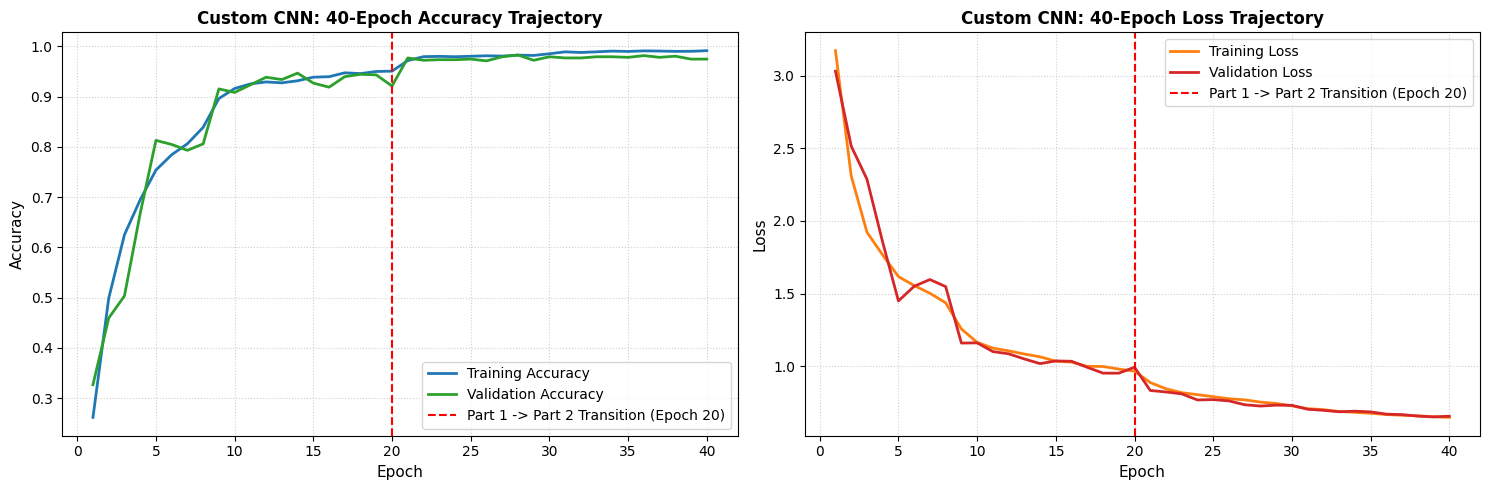

✓ Saved combined 40-epoch training curves to: D:\cnn_model\results\plots\cnn_training_history_40epochs.png


In [9]:
# Load histories if re-running cell independently
part1_file = os.path.join(CONFIG['reports_dir'], 'custom_cnn_part1_history.json')
part2_file = os.path.join(CONFIG['reports_dir'], 'custom_cnn_part2_history.json')

acc_combined = []
val_acc_combined = []
loss_combined = []
val_loss_combined = []

if os.path.exists(part1_file):
    with open(part1_file, 'r') as f:
        h1 = json.load(f)
    acc_combined.extend(h1.get('accuracy', []))
    val_acc_combined.extend(h1.get('val_accuracy', []))
    loss_combined.extend(h1.get('loss', []))
    val_loss_combined.extend(h1.get('val_loss', []))

if os.path.exists(part2_file):
    with open(part2_file, 'r') as f:
        h2 = json.load(f)
    acc_combined.extend(h2.get('accuracy', []))
    val_acc_combined.extend(h2.get('val_accuracy', []))
    loss_combined.extend(h2.get('loss', []))
    val_loss_combined.extend(h2.get('val_loss', []))

combined_history = {
    'accuracy': acc_combined,
    'val_accuracy': val_acc_combined,
    'loss': loss_combined,
    'val_loss': val_loss_combined
}

# Save full 40-epoch combined history
with open(os.path.join(CONFIG['reports_dir'], 'cnn_baseline_history.json'), 'w') as f:
    json.dump(combined_history, f, indent=4)

# Plot Combined 40-Epoch History
epochs_range = range(1, len(acc_combined) + 1)

plt.figure(figsize=(15, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc_combined, label='Training Accuracy', color='#1f77b4', lw=2)
plt.plot(epochs_range, val_acc_combined, label='Validation Accuracy', color='#2ca02c', lw=2)
if len(acc_combined) >= 20:
    plt.axvline(x=20, color='red', linestyle='--', label='Part 1 -> Part 2 Transition (Epoch 20)')
plt.title('Custom CNN: 40-Epoch Accuracy Trajectory', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Accuracy', fontsize=11)
plt.legend(frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss_combined, label='Training Loss', color='#ff7f0e', lw=2)
plt.plot(epochs_range, val_loss_combined, label='Validation Loss', color='#d62728', lw=2)
if len(loss_combined) >= 20:
    plt.axvline(x=20, color='red', linestyle='--', label='Part 1 -> Part 2 Transition (Epoch 20)')
plt.title('Custom CNN: 40-Epoch Loss Trajectory', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Loss', fontsize=11)
plt.legend(frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
history_plot_path = os.path.join(CONFIG['plots_dir'], 'cnn_training_history_40epochs.png')
plt.savefig(history_plot_path, dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(CONFIG['plots_dir'], 'cnn_training_history.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Saved combined 40-epoch training curves to: {history_plot_path}")


### Step 8: Comprehensive Test Set Evaluation (All 40 Classes)

In [10]:
print("Evaluating best model on test set...\n")

# Load best checkpoint for evaluation
best_path = os.path.join(CONFIG['models_dir'], 'best_model.h5')
if os.path.exists(best_path):
    eval_model = keras.models.load_model(best_path)
else:
    eval_model = model

y_true = []
y_pred = []

for test_imgs, test_lbls in test_ds:
    preds = eval_model.predict(test_imgs, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(test_lbls.numpy(), axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Import metric functions
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Compute standard metrics
accuracy = float(accuracy_score(y_true, y_pred))
precision = float(precision_score(y_true, y_pred, average='weighted', zero_division=0))
recall = float(recall_score(y_true, y_pred, average='weighted', zero_division=0))
f1 = float(f1_score(y_true, y_pred, average='weighted', zero_division=0))
cm = confusion_matrix(y_true, y_pred, labels=range(CONFIG['num_classes']))

metrics = {
    'accuracy': accuracy,
    'precision': precision,
    'recall': recall,
    'f1_score': f1,
    'confusion_matrix': cm.tolist()
}

# Save metrics JSON
metrics_path = os.path.join(CONFIG['reports_dir'], 'cnn_baseline_metrics.json')
with open(metrics_path, 'w') as f:
    json.dump(metrics, f, indent=4)

print("=" * 70)
print("🏆 FINAL TEST SET EVALUATION RESULTS")
print("=" * 70)
print(f"  Accuracy:  {accuracy*100:.2f}%")
print(f"  Precision: {precision*100:.2f}%")
print(f"  Recall:    {recall*100:.2f}%")
print(f"  F1-Score:  {f1*100:.2f}%")
print("=" * 70)


Evaluating best model on test set...



NameError: name 'precision_score' is not defined

### Step 9: Plot Confusion Matrix & Per-Class Breakdown

In [ ]:
# Plot Normalized Confusion Matrix
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
cm_norm = np.nan_to_num(cm_norm)

plt.figure(figsize=(16, 14))
sns.heatmap(
    cm_norm,
    annot=False,
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title(f'Custom CNN: Confusion Matrix (Test Accuracy: {accuracy*100:.2f}%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()

cm_plot_path = os.path.join(CONFIG['plots_dir'], 'cnn_confusion_matrix.png')
plt.savefig(cm_plot_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Saved confusion matrix plot to: {cm_plot_path}")


### Step 10: Performance Summary & Next Pipeline Steps

In [ ]:
print("=" * 75)
print("🎉 CUSTOM CNN 40-EPOCH TRAINING WORKFLOW COMPLETE")
print("=" * 75)
print(f"\n📊 Final Results Summary:")
print(f"  • Model Architecture:  Custom Deep ResCNN (5 Residual Stages + Dual Pooling)")
print(f"  • Total Epochs:        40 Epochs (Part 1: 1-20 + Part 2: 21-40)")
print(f"  • SMOTE Balanced:      {metadata.get('smote_enabled', False)}")
print(f"  • Test Accuracy:       {metrics['accuracy']*100:.2f}%")
print(f"  • Test F1-Score:       {metrics['f1_score']*100:.2f}%")

print(f"\n💾 Saved Artifacts:")
print(f"  • Final Model:         {CONFIG['models_dir']}/cnn_baseline.h5")
print(f"  • Best Model:          {CONFIG['models_dir']}/best_model.h5")
print(f"  • Part 1 Checkpoint:   {CONFIG['models_dir']}/custom_cnn_part1_epoch20.h5")
print(f"  • Part 2 Checkpoint:   {CONFIG['models_dir']}/custom_cnn_part2_epoch40.h5")
print(f"  • Metrics Report:      {CONFIG['reports_dir']}/cnn_baseline_metrics.json")
print(f"  • Training History:    {CONFIG['reports_dir']}/cnn_baseline_history.json")
print(f"  • History Plot:        {CONFIG['plots_dir']}/cnn_training_history_40epochs.png")

print(f"\n→ Next Step: 06_mobilenet_training.ipynb")
print("=" * 75)
